Bu projede, dünya ülkelerinin askerî güçlerini gösteren veri seti kullanılarak ülkelerin benzer özelliklerine göre gruplandırılması amaçlanmıştır.

Çalışmada öncelikle veri seti incelenmiş, eksik veriler düzenlenmiş ve sayısal değişkenler analiz için hazırlanmıştır. Daha sonra K-Means kümeleme algoritması kullanılarak ülkeler askerî güç özelliklerine göre kümelere ayrılmıştır.

Uygun küme sayısını belirlemek amacıyla Elbow Method yöntemi kullanılmış, farklı küme sayıları Silhouette Score değerleri üzerinden karşılaştırılmıştır. Sonuçlar incelenerek ülkelerin hangi kümelerde yer aldığı değerlendirilmiştir.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Excel dosyasını okuyalım
df = pd.read_excel("World military power.xlsx")

# İlk 5 satırı görüntüleyelim
df.head()



,2020 ranking,Unnamed: 1,Airforce Strength,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 50,Unnamed: 51,Geography,Unnamed: 53,Unnamed: 54,Unnamed: 55,Unnamed: 56,Unnamed: 57,Unnamed: 58,Unnamed: 59
0,Military Strength,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,...,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
1,Afghanistan,1.3444,Afghanistan,260,Afghanistan,0,Afghanistan,25,Afghanistan,30,...,Afghanistan,"3,49,40,837",Afghanistan,"6,52,230",Afghanistan,0,Afghanistan,1200,Afghanistan,5987
2,Albania,2.3137,Albania,19,Albania,0,Albania,0,Albania,0,...,Albania,"30,57,220",Albania,28748,Albania,362,Albania,41,Albania,691
3,Algeria,0.4659,Algeria,551,Algeria,103,Algeria,22,Algeria,59,...,Algeria,"4,16,57,488",Algeria,"23,81,741",Algeria,998,Algeria,0,Algeria,6734
4,Angola,0.8379,Angola,295,Angola,72,Angola,18,Angola,30,...,Angola,"3,03,55,880",Angola,"12,46,700",Angola,1600,Angola,1300,Angola,5369


In [2]:

# Satır ve sütun sayısı
df.shape

# Sütun adları ve veri tipleri
df.info()

# Sayısal sütunların istatistikleri
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 60 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   2020 ranking       139 non-null    str   
 1   Unnamed: 1         139 non-null    object
 2   Airforce Strength  139 non-null    str   
 3   Unnamed: 3         139 non-null    object
 4   Unnamed: 4         139 non-null    str   
 5   Unnamed: 5         139 non-null    object
 6   Unnamed: 6         139 non-null    str   
 7   Unnamed: 7         139 non-null    object
 8   Unnamed: 8         139 non-null    str   
 9   Unnamed: 9         139 non-null    object
 10  Unnamed: 10        139 non-null    str   
 11  Unnamed: 11        139 non-null    object
 12  Unnamed: 12        139 non-null    str   
 13  Unnamed: 13        139 non-null    object
 14  Unnamed: 14        139 non-null    str   
 15  Unnamed: 15        139 non-null    object
 16  Land Strength      139 non-null    str   
 17  Unnamed:

,2020 ranking,Unnamed: 1,Airforce Strength,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 50,Unnamed: 51,Geography,Unnamed: 53,Unnamed: 54,Unnamed: 55,Unnamed: 56,Unnamed: 57,Unnamed: 58,Unnamed: 59
count,139,139,139,139,139,139,139,139,139,139,...,139,139,139,139,110,110,139,139,130,130
unique,139,139,139,114,139,64,139,39,139,50,...,139,139,139,139,110,105,139,93,130,126
top,Military Strength,Military Strength Power Index,Aircraft Strength,19,Fighter/Interceptor Strength,0,Attack Aircraft Strength,0,Transport Aircraft Fleet Strength,0,...,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,400,Total Waterway Coverage,0,Total Border Coverage,2237
freq,1,1,1,5,1,46,1,75,1,15,...,1,1,1,1,1,2,1,38,1,2


In [3]:
# Excel dosyasını gerçek sütun başlıklarıyla okuyalım
df = pd.read_excel("World military power.xlsx", header=1)

# Sütun adlarını kontrol edelim
df.columns

# İlk 5 satırı görüntüleyelim
df.head()

,Military Strength,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,...,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
0,Afghanistan,1.3444,Afghanistan,260,Afghanistan,0,Afghanistan,25,Afghanistan,30,...,Afghanistan,"3,49,40,837",Afghanistan,"6,52,230",Afghanistan,0,Afghanistan,1200,Afghanistan,5987.0
1,Albania,2.3137,Albania,19,Albania,0,Albania,0,Albania,0,...,Albania,"30,57,220",Albania,28748,Albania,362,Albania,41,Albania,691.0
2,Algeria,0.4659,Algeria,551,Algeria,103,Algeria,22,Algeria,59,...,Algeria,"4,16,57,488",Algeria,"23,81,741",Algeria,998,Algeria,0,Algeria,6734.0
3,Angola,0.8379,Angola,295,Angola,72,Angola,18,Angola,30,...,Angola,"3,03,55,880",Angola,"12,46,700",Angola,1600,Angola,1300,Angola,5369.0
4,Argentina,0.6521,Argentina,227,Argentina,24,Argentina,7,Argentina,9,...,Argentina,"4,46,94,198",Argentina,"27,80,400",Argentina,4989,Argentina,11000,Argentina,11968.0


In [4]:

# Veri setinin boyutu
print("Veri setinin boyutu:", df.shape)

# Sütunların veri tipleri
df.info()

# Eksik değer sayıları
df.isnull().sum()


Veri setinin boyutu: (138, 60)
<class 'pandas.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 60 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Military Strength                        138 non-null    str    
 1   Military Strength Power Index            138 non-null    float64
 2   Aircraft Strength                        138 non-null    str    
 3   Aircraft Strength value                  138 non-null    int64  
 4   Fighter/Interceptor Strength             138 non-null    str    
 5   Fighter/Interceptor Strength value       138 non-null    int64  
 6   Attack Aircraft Strength                 138 non-null    str    
 7   Attack Aircraft Strength value           138 non-null    int64  
 8   Transport Aircraft Fleet Strength        138 non-null    str    
 9   Transport Aircraft Fleet Strength value  138 non-null    int64  
 10  Trainer Aircraft Fleet        

Military Strength                           0
Military Strength Power Index               0
Aircraft Strength                           0
Aircraft Strength value                     0
Fighter/Interceptor Strength                0
Fighter/Interceptor Strength value          0
Attack Aircraft Strength                    0
Attack Aircraft Strength value              0
Transport Aircraft Fleet Strength           0
Transport Aircraft Fleet Strength value     0
Trainer Aircraft Fleet                      0
Trainer Aircraft Fleet value                0
Helicopter Fleet Strength                   0
Helicopter Fleet Strength value             0
Attack Helicopter Fleet Strength            0
Attack Helicopter Fleet Strength value      0
Tank Strength                               0
Tank Strength value                         0
AFV/APC Strength                            0
AFV/APC Strength value                      0
Self-Propelled Artillery Strength           0
Self-Propelled Artillery Strength 

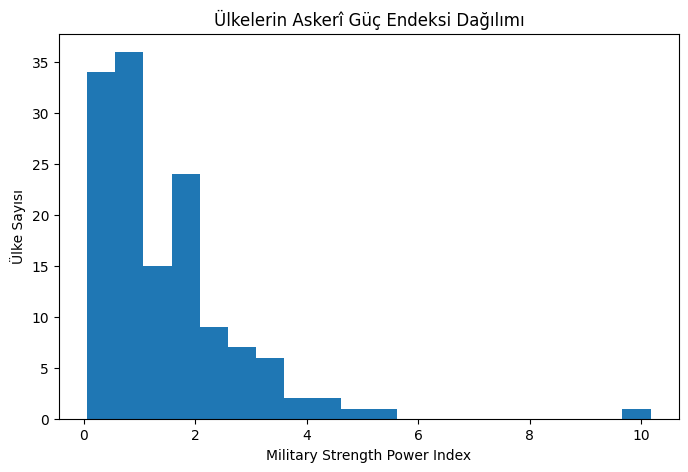

In [5]:
# Askerî güç endeksinin dağılımı
plt.figure(figsize=(8, 5))
plt.hist(df["Military Strength Power Index"], bins=20)
plt.title("Ülkelerin Askerî Güç Endeksi Dağılımı")
plt.xlabel("Military Strength Power Index")
plt.ylabel("Ülke Sayısı")
plt.show()

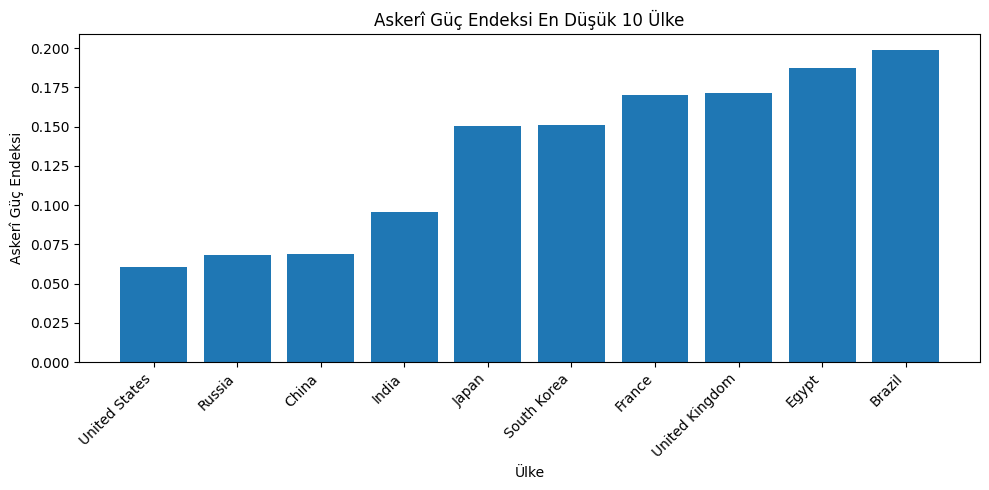

In [6]:
# Askerî güç endeksi en düşük olan ülkeler daha güçlü kabul edilir.
# Bu nedenle endeksin en küçük değerlerini gösteriyoruz.
ilk_10 = df.nsmallest(10, "Military Strength Power Index")

plt.figure(figsize=(10, 5))
plt.bar(
    ilk_10["Military Strength"],ilk_10["Military Strength Power Index"])
plt.title("Askerî Güç Endeksi En Düşük 10 Ülke")
plt.xlabel("Ülke")
plt.ylabel("Askerî Güç Endeksi")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

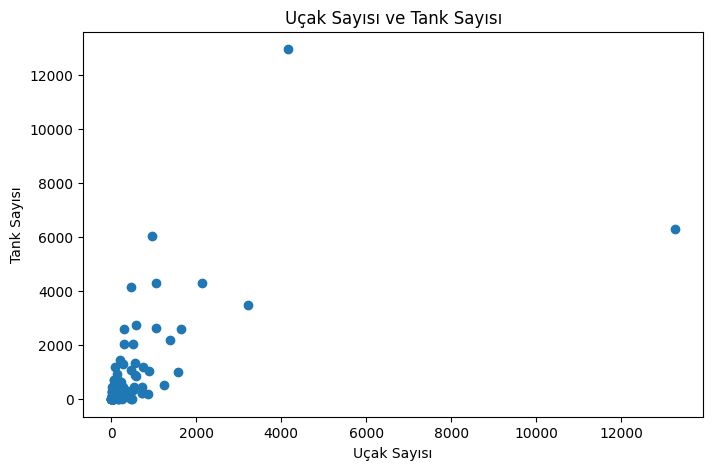

In [7]:
# Uçak ve tank sayılarının karşılaştırılması
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Aircraft Strength value"],df["Tank Strength value"])
plt.title("Uçak Sayısı ve Tank Sayısı")
plt.xlabel("Uçak Sayısı")
plt.ylabel("Tank Sayısı")
plt.show()


In [8]:
# Sayısal veri türündeki sütunları listeleme
sayisal_sutunlar = df.select_dtypes(include=["int64", "float64"]).columns

len(sayisal_sutunlar), sayisal_sutunlar.tolist()


(20,
 ['Military Strength Power Index',
  'Aircraft Strength value',
  'Fighter/Interceptor Strength value',
  'Attack Aircraft Strength value',
  'Transport Aircraft Fleet Strength value',
  'Trainer Aircraft Fleet value',
  'Helicopter Fleet Strength value',
  'Attack Helicopter Fleet Strength value',
  'Tank Strength value',
  'AFV/APC Strength value',
  'Self-Propelled Artillery Strength value',
  'Towed Artillery Strength value',
  'Rocket Projector Strength value',
  'Navy Fleet Strengths value',
  'Aircraft Carrier Fleet Strength value',
  'Submarine Fleet Strength value',
  'Destroyer Fleet Strength value',
  'Frigate Fleet Strength value',
  'Airport Totals value',
  'Total Border Coverage value'])

In [9]:
# Sayısal sütunların ilk 5 satırını inceleme
df[sayisal_sutunlar].head()


,Military Strength Power Index,Aircraft Strength value,Fighter/Interceptor Strength value,Attack Aircraft Strength value,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet value,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength value,Tank Strength value,AFV/APC Strength value,Self-Propelled Artillery Strength value,Towed Artillery Strength value,Rocket Projector Strength value,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength value,Destroyer Fleet Strength value,Frigate Fleet Strength value,Airport Totals value,Total Border Coverage value
0,1.3444,260,0,25,30,0,187,0,0,1062,0,176,50,0.0,0.0,0.0,0.0,0.0,43,5987.0
1,2.3137,19,0,0,0,0,19,0,0,467,0,0,0,38.0,0.0,0.0,0.0,0.0,4,691.0
2,0.4659,551,103,22,59,87,257,45,880,7361,320,240,316,201.0,0.0,6.0,0.0,5.0,157,6734.0
3,0.8379,295,72,18,30,47,126,15,379,595,28,357,115,57.0,0.0,0.0,0.0,0.0,176,5369.0
4,0.6521,227,24,7,9,64,100,0,370,739,83,172,26,49.0,0.0,2.0,4.0,0.0,1138,11968.0


In [10]:
# Ülke isimlerini ayrı tutma
ulkeler = df["Military Strength"]

# Kümeleme için sayısal sütunları seçme
X = df.select_dtypes(include=["int64", "float64"])

# Eksik değerleri kontrol etme
X.shape, X.isnull().sum().sum()

# İlk 5 satırı görüntüleme
X.head()

,Military Strength Power Index,Aircraft Strength value,Fighter/Interceptor Strength value,Attack Aircraft Strength value,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet value,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength value,Tank Strength value,AFV/APC Strength value,Self-Propelled Artillery Strength value,Towed Artillery Strength value,Rocket Projector Strength value,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength value,Destroyer Fleet Strength value,Frigate Fleet Strength value,Airport Totals value,Total Border Coverage value
0,1.3444,260,0,25,30,0,187,0,0,1062,0,176,50,0.0,0.0,0.0,0.0,0.0,43,5987.0
1,2.3137,19,0,0,0,0,19,0,0,467,0,0,0,38.0,0.0,0.0,0.0,0.0,4,691.0
2,0.4659,551,103,22,59,87,257,45,880,7361,320,240,316,201.0,0.0,6.0,0.0,5.0,157,6734.0
3,0.8379,295,72,18,30,47,126,15,379,595,28,357,115,57.0,0.0,0.0,0.0,0.0,176,5369.0
4,0.6521,227,24,7,9,64,100,0,370,739,83,172,26,49.0,0.0,2.0,4.0,0.0,1138,11968.0


Eksik değerlerin incelenmesi

Sayısal sütunlardaki eksik değerler deniz kuvveti ve kara sınırı sütunlarında bulunmaktadır:
- Deniz filosu (Navy Fleet Strengths value) bilgisi eksik olan 14 ülkenin tamamı denize kıyısı olmayan ülkelerdir (ör. Çad, Etiyopya, Macaristan, Moğolistan, Nepal). Bu ülkelerin deniz kuvveti bulunmadığı için uçak gemisi, denizaltı, muhrip ve fırkateyn sayıları da eksiktir.
- Kara sınırı (Total Border Coverage value) bilgisi eksik olan 9 ülkenin tamamı ada ülkesidir (ör. Avustralya, Japonya, Yeni Zelanda, Filipinler).

Bu ülkelerin eksik değerleri sütun medyanıyla doldurulursa, deniz kuvveti olmayan bir ülkeye ortalama sayıda gemi atanmış olur ve veri yanlış temsil edilir. Ülkeleri veri setinden çıkarmak ise veri kaybına yol açar. Bu nedenle eksik değerler fillna(0) ile 0 olarak doldurulmuştur.

Not: Güney Kore'nin toplam deniz filosu bilgisi (234) bulunmakla birlikte denizaltı, muhrip ve fırkateyn sayıları veri setinde eksiktir. Bu ülke için 0 değeri gerçek durumu tam yansıtmamaktadır.

In [11]:
# Eksik değerleri 0 ile doldurma
# Deniz filosu bilgisi eksik olan ülkeler denize kıyısı olmayan ülkelerdir; bu ülkelerin gemisi olmadığı için doğru değer 0'dır.
# Kara sınırı bilgisi eksik olan ülkeler ada ülkeleridir; bu ülkelerin kara sınırı olmadığı için doğru değer 0'dır.
X = X.fillna(0)

# Eksik değer ve veri boyutunu kontrol etme
X.isnull().sum().sum(), X.shape

(np.int64(0), (138, 20))

In [12]:
from sklearn.preprocessing import StandardScaler

# Sayısal verileri ölçeklendirme
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled.shape


(138, 20)

In [13]:
#K-Means Kümele

In [14]:
from sklearn.cluster import KMeans

# K-Means modelini oluşturma
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Modeli eğitme ve küme numaralarını belirleme
kume_no = kmeans.fit_predict(X_scaled)

# Küme numaralarını veri setine ekleme
df["Küme"] = kume_no

# İlk 10 ülkenin kümesini görüntüleme
df[["Military Strength", "Küme"]].head(10)


,Military Strength,Küme
0,Afghanistan,0
1,Albania,0
2,Algeria,0
3,Angola,0
4,Argentina,0
5,Armenia,0
6,Australia,0
7,Austria,0
8,Azerbaijan,0
9,Bahrain,0


In [15]:
# Her kümede kaç ülke olduğunu sayma
print(df["Küme"].value_counts().sort_index())

Küme
0    135
1      2
2      1
Name: count, dtype: int64


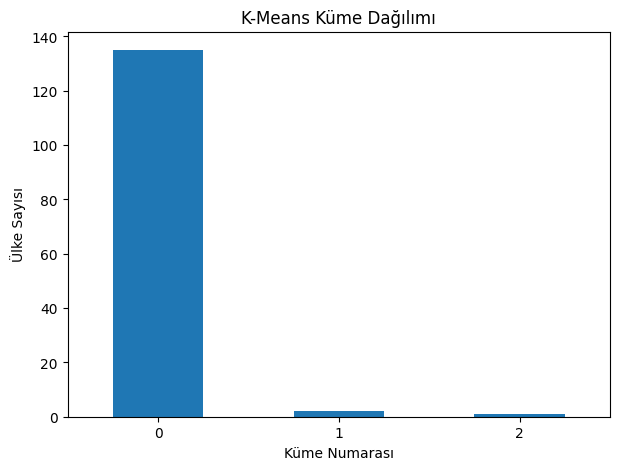

In [16]:
# Küme dağılımını grafikle gösterme
df["Küme"].value_counts().sort_index().plot(kind="bar",figsize=(7, 5))

plt.title("K-Means Küme Dağılımı")
plt.xlabel("Küme Numarası")
plt.ylabel("Ülke Sayısı")
plt.xticks(rotation=0)
plt.show()

In [17]:
df[df["Military Strength"] == "Turkey"][["Military Strength", "Küme"]]

,Military Strength,Küme
124,Turkey,0


In [18]:
# Her kümede kaç ülke olduğunu sayma
df["Küme"].value_counts().sort_index()

Küme
0    135
1      2
2      1
Name: count, dtype: int64

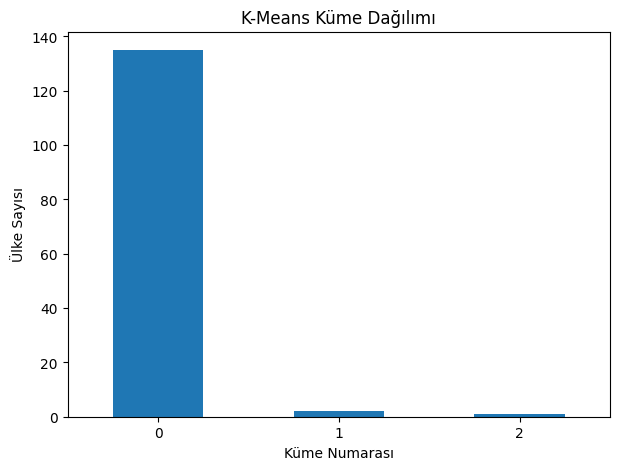

In [19]:
# Küme dağılımını grafikle gösterme
df["Küme"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("K-Means Küme Dağılımı")
plt.xlabel("Küme Numarası")
plt.ylabel("Ülke Sayısı")
plt.xticks(rotation=0)
plt.show()

In [20]:

# Her kümedeki ülkeleri listeleme
df.groupby("Küme")["Military Strength"].apply(list)


Küme
0    [Afghanistan, Albania, Algeria, Angola, Argent...
1                                      [China, Russia]
2                                      [United States]
Name: Military Strength, dtype: object

In [21]:
# Küme merkezlerini görüntüleme
kume_merkezleri = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),columns=X.columns)

kume_merkezleri

,Military Strength Power Index,Aircraft Strength value,Fighter/Interceptor Strength value,Attack Aircraft Strength value,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet value,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength value,Tank Strength value,AFV/APC Strength value,Self-Propelled Artillery Strength value,Towed Artillery Strength value,Rocket Projector Strength value,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength value,Destroyer Fleet Strength value,Frigate Fleet Strength value,Airport Totals value,Total Border Coverage value
0,1.491711,244.237037,52.340741,12.792593,19.103704,59.088889,96.740741,13.014815,492.496296,1805.444444,132.814815,322.696296,102.081481,64.207407,0.155556,2.592593,0.688889,2.540741,183.614815,3366.459259
1,0.068600,3686.500000,1052.500000,556.500000,324.000000,405.500000,1216.500000,406.000000,8225.000000,30019.000000,4941.500000,4032.500000,3255.000000,690.000000,1.500000,68.000000,26.000000,31.000000,862.500000,22432.500000
2,0.060600,13264.000000,2085.000000,715.000000,945.000000,2643.000000,5768.000000,967.000000,6289.000000,39253.000000,1465.000000,2740.000000,1366.000000,490.000000,20.000000,66.000000,91.000000,0.000000,13513.000000,12048.000000


In [22]:
# Farklı küme sayıları için K-Means sonuçları
for i in range(1, 7):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(X_scaled)
    sonuc = f"Küme sayısı: {i} Inertia: {model.inertia_}"
    display(sonuc)

'Küme sayısı: 1 Inertia: 2759.9999999999995'

'Küme sayısı: 2 Inertia: 1365.1200513021515'

'Küme sayısı: 3 Inertia: 913.3656742586669'

'Küme sayısı: 4 Inertia: 673.5262945721635'

'Küme sayısı: 5 Inertia: 564.4952212239224'

'Küme sayısı: 6 Inertia: 492.1234650694082'

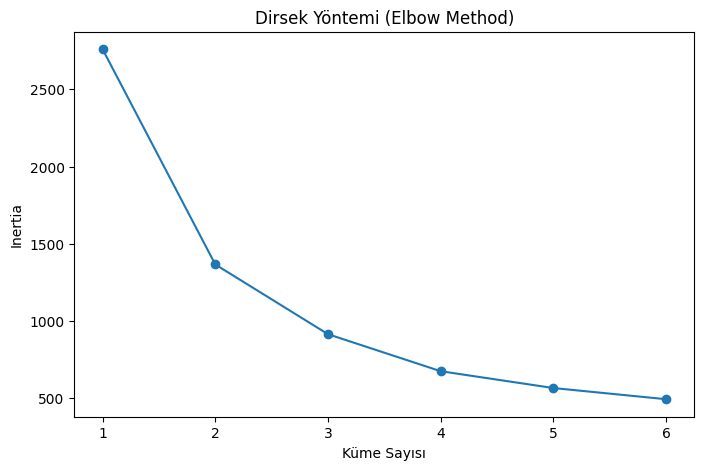

In [23]:
# Dirsek yöntemi grafiği
inertia_degerleri = []

for i in range(1, 7):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_degerleri.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 7), inertia_degerleri, marker="o")
plt.title("Dirsek Yöntemi (Elbow Method)")
plt.xlabel("Küme Sayısı")
plt.ylabel("Inertia")
plt.xticks(range(1, 7))
plt.show()

In [24]:

# 4 kümeli K-Means modeli
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

# Ülkelerin küme numaralarını belirleme
kume_no_4 = kmeans_4.fit_predict(X_scaled)

# Küme dağılımını görüntüleme
pd.Series(kume_no_4).value_counts().sort_index()

0    111
1      1
2      2
3     24
Name: count, dtype: int64

In [25]:
# Ülkeleri 4 kümeye göre listeleme
df.groupby(kume_no_4)["Military Strength"].apply(list)


0    [Afghanistan, Albania, Angola, Argentina, Arme...
1                                      [United States]
2                                      [China, Russia]
3    [Algeria, Brazil, Colombia, Egypt, France, Gre...
Name: Military Strength, dtype: object

In [26]:
from sklearn.metrics import silhouette_score

# 3 kümeli modelin Silhouette skoru
skor_3 = silhouette_score(X_scaled, kume_no)

# 4 kümeli modelin Silhouette skoru
skor_4 = silhouette_score(X_scaled, kume_no_4)

skor_3, skor_4

(0.8412455578817905, 0.4936560845312548)

#Bu ne anlama geliyor?
- 3 kümeli modelin 0,8412 skoru, kümelerin kullanılan özellikler bakımından oldukça iyi ayrıştığına işaret ediyor.
- 4 kümeli modelin 0,4937 skoru ise ayrışmanın daha zayıf olduğunu gösteriyor.
- Bu nedenle mevcut sonuçlarla, 3 kümeli model daha uygun bir aday görünüyor.
Ancak önemli bir ayrıntı var: 3 kümeli modelde 135 ülke bir kümede, Çin ve Rusya ikinci kümede, ABD ise üçüncü kümede yer alıyor. Dolayısıyla yüksek Silhouette skoru, mutlaka dengeli veya askerî açıdan anlamlı gruplar elde ettiğimiz anlamına gelmez. Uç değerler de bu skoru yükseltebilir.

In [27]:
# 3 kümeli modelin sonuçlarını tabloya ekleme
sonuc_df = df[["Military Strength"]].copy()
sonuc_df["Küme"] = kume_no

# Her kümedeki ülke sayısı
sonuc_df["Küme"].value_counts().sort_index()

# Türkiye'nin kümesini gösterme
sonuc_df[sonuc_df["Military Strength"] == "Turkey"]

,Military Strength,Küme
124,Turkey,0


Ülkelerin kümelere göre dağılımı

Bu bölümde her ülkenin hangi kümede yer aldığı, 3 kümeli ve 4 kümeli modeller için birlikte gösterilmektedir. Önce bütün ülkeleri içeren bir sonuç tablosu oluşturulmuş, ardından her kümedeki ülkeler tam liste olarak yazdırılmış ve son olarak bütün ülkeler tek bir grafikte gösterilmiştir.

In [28]:
# Her ülkenin 3 ve 4 kümeli modeldeki küme numarasını içeren sonuç tablosu
sonuc_tablosu = df[["Military Strength", "Military Strength Power Index"]].copy()
sonuc_tablosu["Küme (3 kümeli model)"] = kume_no
sonuc_tablosu["Küme (4 kümeli model)"] = kume_no_4

# Ülkeleri askerî güç endeksine göre sıralama (endeks küçüldükçe ülke daha güçlüdür)
sonuc_tablosu = sonuc_tablosu.sort_values("Military Strength Power Index")

# Askerî gücü en yüksek 30 ülkenin kümeleri
sonuc_tablosu.head(30)

,Military Strength,Military Strength Power Index,Küme (3 kümeli model),Küme (4 kümeli model)
130,United States,0.0606,2,1
101,Russia,0.0681,1,2
26,China,0.0691,1,2
49,India,0.0953,0,3
57,Japan,0.1501,0,3
110,South Korea,0.1509,0,3
40,France,0.1702,0,3
129,United Kingdom,0.1717,0,3
35,Egypt,0.1872,0,3
17,Brazil,0.1988,0,3


In [29]:
# Türkiye'nin iki modeldeki kümesi
sonuc_tablosu[sonuc_tablosu["Military Strength"] == "Turkey"]

,Military Strength,Military Strength Power Index,Küme (3 kümeli model),Küme (4 kümeli model)
124,Turkey,0.2098,0,3


In [30]:
# 3 kümeli modelde her kümedeki ülkeleri tam liste olarak yazdırma
for k in sorted(sonuc_tablosu["Küme (3 kümeli model)"].unique()):
    ulke_listesi = sonuc_tablosu[sonuc_tablosu["Küme (3 kümeli model)"] == k]["Military Strength"].tolist()
    print(f"Küme {k} ({len(ulke_listesi)} ülke): " + ", ".join(ulke_listesi))
    print()

Küme 0 (135 ülke): India, Japan, South Korea, France, United Kingdom, Egypt, Brazil, Turkey, Italy, Germany, Iran, Pakistan, Indonesia, Saudi Arabia, Israel, Australia, Spain, Poland, Vietnam, Thailand, Canada, North Korea, Taiwan, Ukraine, Algeria, South Africa, Switzerland, Norway, Sweden, Greece, Czechia, Myanmar, Netherlands, Colombia, Mexico, Romania, Peru, Venezuela, Nigeria, Argentina, Malaysia, United Arab Emirates, Bangladesh, Chile, Philippines, Denmark, Iraq, Singapore, Uzbekistan, Belarus, Hungary, Syria, Angola, Morocco, Slovakia, Finland, Ethiopia, Portugal, Bulgaria, Kazakhstan, Azerbaijan, Serbia, Austria, Bolivia, Ecuador, Croatia, Belgium, Democratic Republic of the Congo, Jordan, Cuba, Yemen, Oman, Sudan, Turkmenistan, Afghanistan, New Zealand, Libya, Tunisia, Sri Lanka, Lithuania, Kenya, Kuwait, Uganda, Chad, Zambia, Georgia, Qatar, Zimbabwe, Guatemala, Bahrain, Tajikistan, Uruguay, Mali, Burkina Faso, Kyrgyzstan, Ireland, Slovenia, Cameroon, Latvia, Niger, Ivory Co

In [31]:
# 4 kümeli modelde her kümedeki ülkeleri tam liste olarak yazdırma
for k in sorted(sonuc_tablosu["Küme (4 kümeli model)"].unique()):
    ulke_listesi = sonuc_tablosu[sonuc_tablosu["Küme (4 kümeli model)"] == k]["Military Strength"].tolist()
    print(f"Küme {k} ({len(ulke_listesi)} ülke): " + ", ".join(ulke_listesi))
    print()

Küme 0 (111 ülke): Germany, Australia, Spain, Poland, Canada, South Africa, Switzerland, Norway, Sweden, Czechia, Netherlands, Mexico, Romania, Peru, Venezuela, Nigeria, Argentina, Malaysia, United Arab Emirates, Bangladesh, Chile, Philippines, Denmark, Iraq, Singapore, Uzbekistan, Belarus, Hungary, Angola, Morocco, Slovakia, Finland, Ethiopia, Portugal, Bulgaria, Kazakhstan, Azerbaijan, Serbia, Austria, Bolivia, Ecuador, Croatia, Belgium, Democratic Republic of the Congo, Jordan, Cuba, Yemen, Oman, Sudan, Turkmenistan, Afghanistan, New Zealand, Libya, Tunisia, Sri Lanka, Lithuania, Kenya, Kuwait, Uganda, Chad, Zambia, Georgia, Qatar, Zimbabwe, Guatemala, Bahrain, Tajikistan, Uruguay, Mali, Burkina Faso, Kyrgyzstan, Ireland, Slovenia, Cameroon, Latvia, Niger, Ivory Coast, Mongolia, Ghana, Cambodia, Botswana, Tanzania, Honduras, Armenia, Moldova, Paraguay, Nicaragua, Albania, Mozambique, South Sudan, Lebanon, Estonia, Dominican Republic, Republic of the Congo, Nepal, Montenegro, Maurita

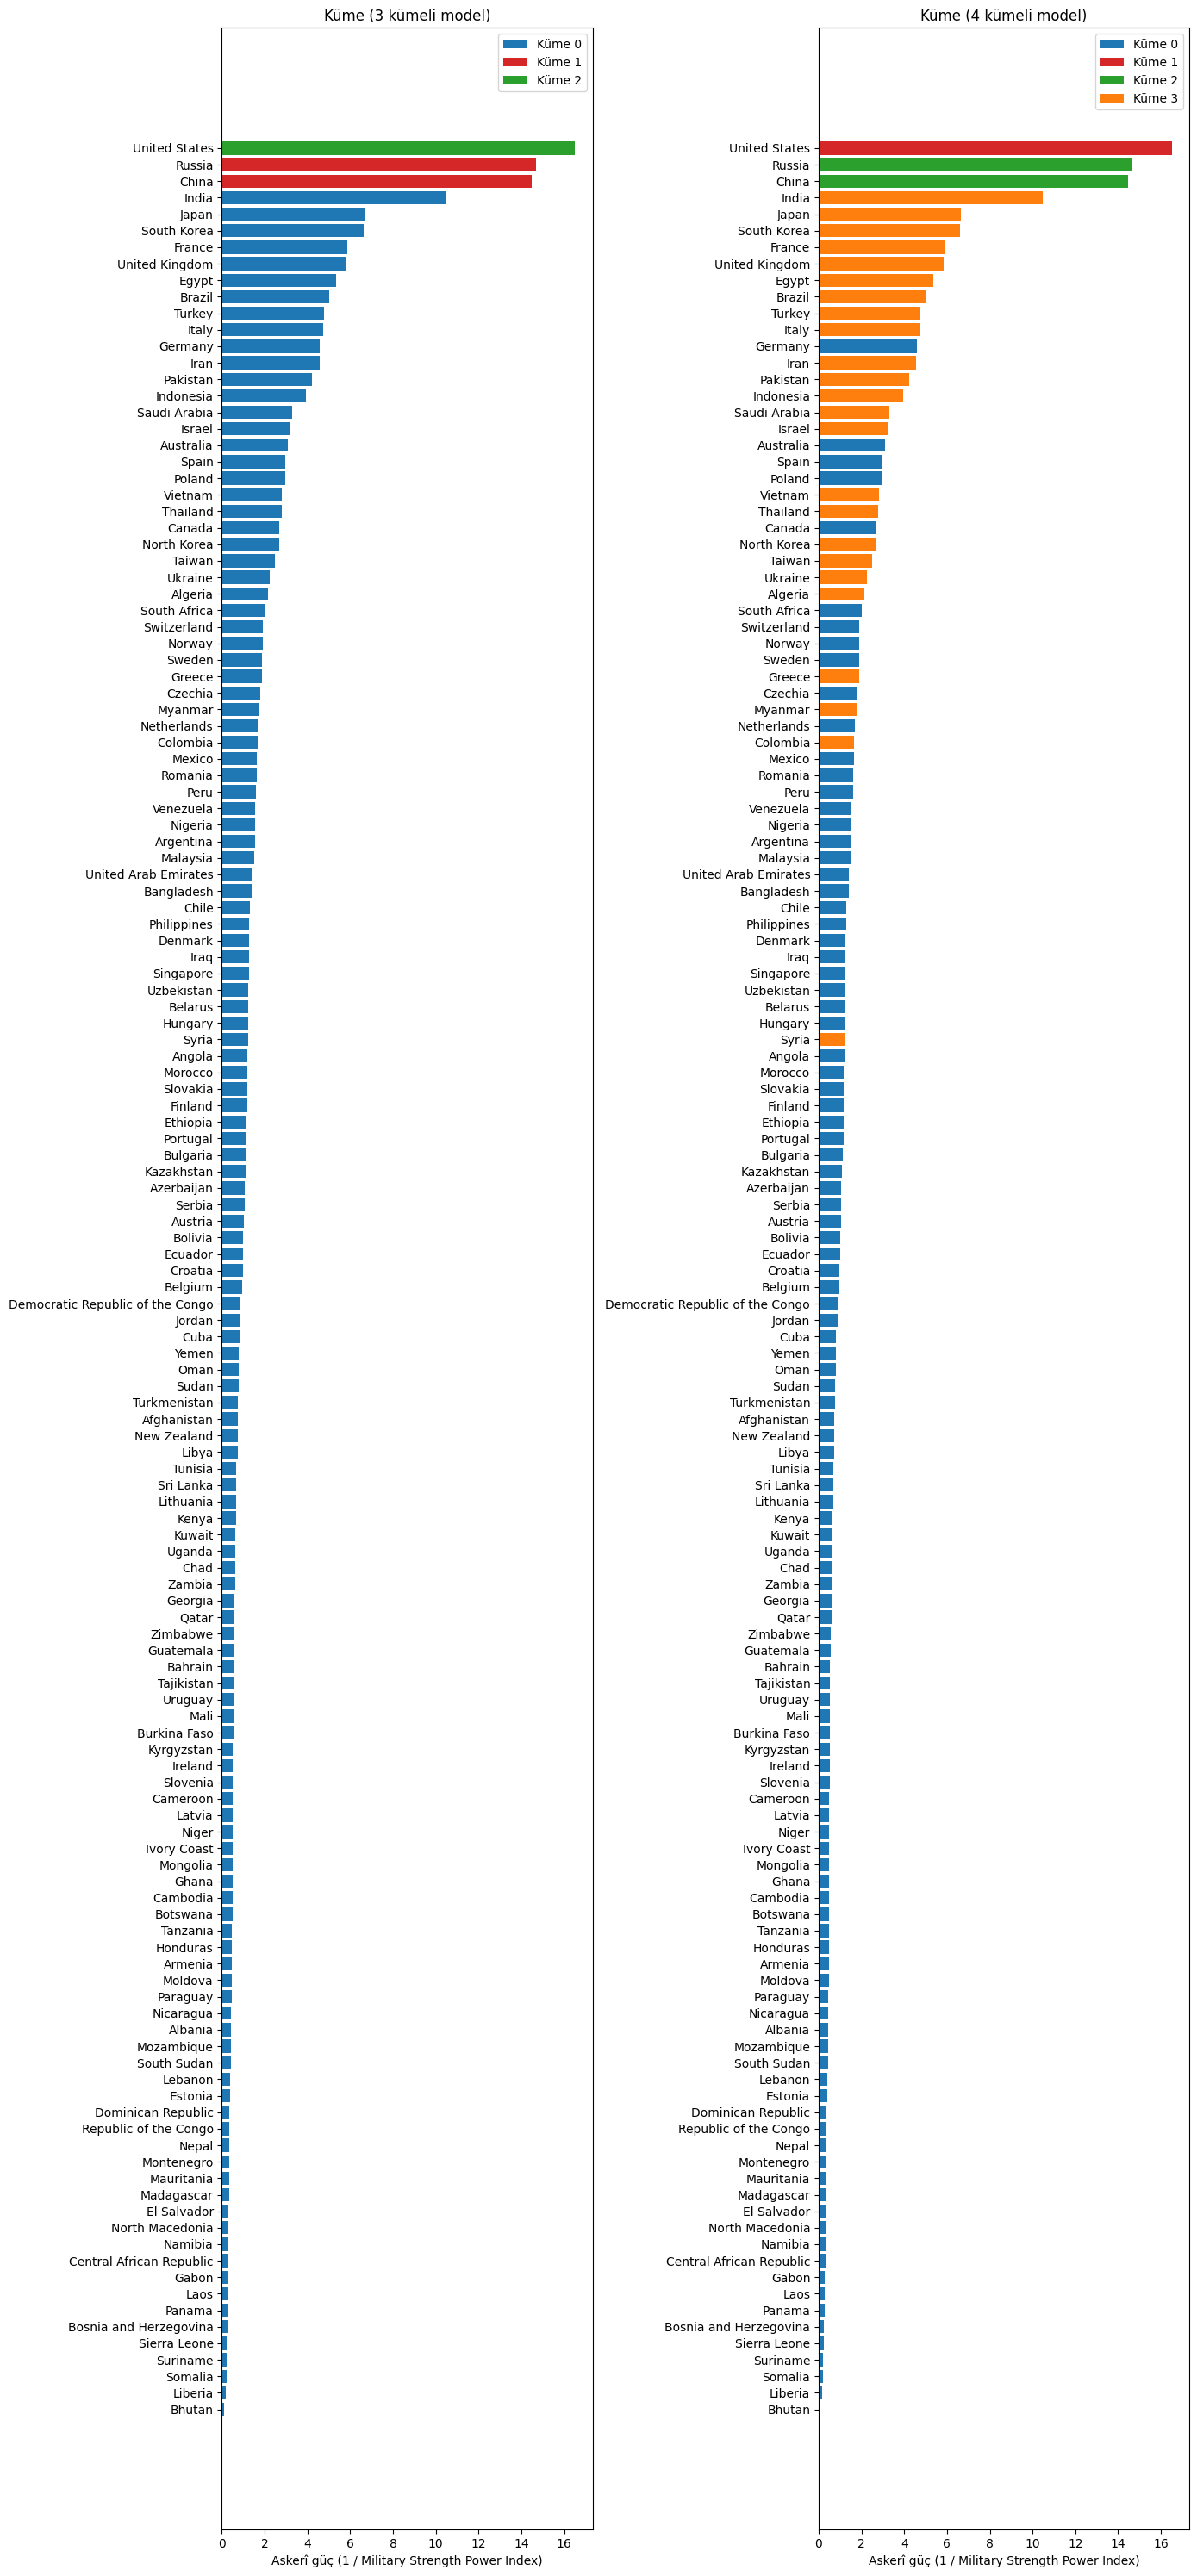

In [32]:
# Grafikte uzun çubuğun güçlü ülkeyi göstermesi için güç endeksinin tersini kullanma
# (endeks küçüldükçe ülke daha güçlü olduğu için 1 / endeks büyüdükçe ülke daha güçlüdür)
grafik = sonuc_tablosu.reset_index(drop=True)
grafik["Askerî güç (1 / endeks)"] = 1 / grafik["Military Strength Power Index"]

# Kümelerin renkleri
renkler = {0: "tab:blue", 1: "tab:red", 2: "tab:green", 3: "tab:orange"}

# Sol grafik 3 kümeli modeli, sağ grafik 4 kümeli modeli göstermektedir
# Ülkeler en güçlüden en zayıfa doğru yukarıdan aşağıya sıralanmıştır
plt.figure(figsize=(14, 30))

for j, model_adi in enumerate(["Küme (3 kümeli model)", "Küme (4 kümeli model)"]):
    plt.subplot(1, 2, j + 1)
    for k in sorted(grafik[model_adi].unique()):
        secilen = grafik[grafik[model_adi] == k]
        plt.barh(secilen.index, secilen["Askerî güç (1 / endeks)"], color=renkler[k], label=f"Küme {k}")
    plt.yticks(grafik.index, grafik["Military Strength"])
    plt.gca().invert_yaxis()
    plt.title(model_adi)
    plt.xlabel("Askerî güç (1 / Military Strength Power Index)")
    plt.legend()

plt.tight_layout()
plt.show()

Grafiğin okunması

Ülkeler askerî gücü en yüksek olandan en düşüğe doğru yukarıdan aşağıya sıralanmıştır; çubuk uzadıkça ülkenin askerî gücü artmaktadır. Her ülkenin rengi, ilgili modelde atandığı kümeyi göstermektedir.

4 kümeli modelde dikkat çekici bir durum görülmektedir: Almanya, Avustralya ve İspanya güç endeksleri yüksek olmasına rağmen 0 numaralı kümede, Suriye ise daha düşük güç endeksine rağmen 3 numaralı kümede yer almaktadır. Bunun nedeni, kümelemenin yalnızca güç endeksine değil, tank, uçak, helikopter ve gemi sayıları gibi 20 sayısal özelliğin tamamına göre yapılmasıdır. Örneğin Suriye'nin tank sayısı yüksek olduğu için bu ülke, kara kuvveti güçlü ülkelerle aynı kümeye girmiştir.

Sonuç ve Değerlendirme

Bu projede, ülkelerin askerî güç özelliklerini incelemek amacıyla K-Means kümeleme algoritması kullanılmıştır. Veri seti 138 ülke ve 60 sütundan oluşmaktadır. Analiz sırasında ülke isimleri dışında kalan uygun sayısal özellikler seçilmiş ve veriler StandardScaler yöntemiyle ölçeklendirilmiştir.

Eksik değerler fillna(0) ile 0 olarak doldurulmuştur. Deniz filosu bilgisi eksik olan ülkelerin tamamı denize kıyısı olmayan, kara sınırı bilgisi eksik olan ülkelerin tamamı ada ülkeleridir. Bu ülkelerin gerçekte gemisi veya kara sınırı bulunmadığından, 0 değeri durumu doğru temsil etmektedir; ülkeler veri setinden çıkarılmadığı için de veri kaybı olmamıştır. Medyan ile doldurma yapılsaydı deniz kuvveti olmayan ülkelere ortalama sayıda gemi atanmış olacaktı. İki yöntem karşılaştırıldığında kümelerdeki ülkeler değişmemiş, Silhouette skorları ise çok az değişmiştir.

Dirsek yöntemiyle farklı küme sayıları incelenmiş, 3 ve 4 kümeli modeller karşılaştırılmıştır. Silhouette skorları 3 kümeli model için 0,8412, 4 kümeli model için 0,4937 olarak hesaplanmıştır. Bu karşılaştırmada 3 kümeli model daha yüksek bir Silhouette skoru vermiştir.

Üç kümeli modelde 135 ülke birinci grupta, Çin ve Rusya ikinci grupta, Amerika Birleşik Devletleri ise üçüncü grupta yer almıştır. Türkiye, 0 numaralı kümeye atanmıştır. Dört kümeli modelde ise 135 ülkelik grup ikiye ayrılmakta ve askerî gücü yüksek 24 ülke (Hindistan, Japonya, Güney Kore, Fransa, İngiltere, Mısır, Brezilya, Türkiye, İtalya, İran, Pakistan ve diğerleri) ayrı bir küme oluşturmaktadır. Türkiye bu modelde 3 numaralı kümede, yani askerî gücü yüksek ülkeler grubunda yer almaktadır. Her ülkenin iki modeldeki kümesi, çalışmanın sonundaki sonuç tablosunda, küme listelerinde ve grafikte gösterilmiştir.

Sonuçlar, seçilen özellikler ve kullanılan algoritma kapsamında ülkelerin belirli gruplara ayrılabildiğini göstermektedir. Bununla birlikte, kümelerin dengesiz dağılımı dikkate alınmalıdır. Yüksek Silhouette skoru tek başına askerî açıdan anlamlı veya dengeli gruplar oluştuğunu kanıtlamaz; 4 kümeli model daha düşük skora rağmen ülkeleri daha ayırt edici gruplara ayırmaktadır. Ayrıca Güney Kore'nin denizaltı, muhrip ve fırkateyn sayıları veri setinde eksik olduğu için bu ülke için 0 değeri gerçek durumu tam yansıtmamaktadır. Farklı özellik seçimleri ve alternatif kümeleme ayarlarıyla ek değerlendirmeler yapılabilir.